# Credit Default Risk - Exploratory Data Analysis

This notebook is **EDA only**. It documents how the data was understood and how each
cleaning decision was reached. It does not train the production model - that lives in
`src/train.py`, so that training is reproducible from the command line and cannot drift
from what the API serves.

Run order:

1. Load the three raw tables and check how they relate.
2. Establish the target and its imbalance.
3. Find and quantify every data-quality problem.
4. Look at where the signal actually is.
5. Investigate why the model scores so highly - the most important section here.

Everything below reads from `src/`, so the numbers in this notebook and the numbers in
the docs cannot disagree.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config
from src.data import load_raw, merge_raw, clean
from src.features import build_features, FEATURE_COLUMNS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

## 1. The three tables and how they relate

`customers` describes the applicant, `loans` describes the product they applied for, and
`bureau_data` is their credit-bureau file. All three join on `cust_id`.

The join is **one-to-one**: each customer appears exactly once in each table, so the merge
neither drops nor duplicates a row. That is worth asserting rather than assuming - a
many-to-one join here would silently inflate the dataset and every metric with it.

In [2]:
customers, loans, bureau = load_raw()
print("customers", customers.shape)
print("loans    ", loans.shape)
print("bureau   ", bureau.shape)

for name, frame in [("customers", customers), ("loans", loans), ("bureau", bureau)]:
    print(f"{name:10} unique cust_id: {frame.cust_id.nunique():,}  duplicated: {frame.cust_id.duplicated().sum()}")

customers (50000, 12)
loans     (50000, 15)
bureau    (50000, 8)
customers  unique cust_id: 50,000  duplicated: 0
loans      unique cust_id: 50,000  duplicated: 0
bureau     unique cust_id: 50,000  duplicated: 0


In [3]:
df = merge_raw(customers, loans, bureau)
print("merged:", df.shape)
df.head(3)

merged: (50000, 33)


,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,loan_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001,L00001,Auto,Secured,3004000,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001,L00002,Home,Secured,4161000,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001,L00003,Personal,Unsecured,2401000,2170000,43400.0,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58


## 2. The target

`default` is boolean. The base rate is **8.594%** - about one loan in twelve goes bad.

This imbalance is the single most important fact about the modelling problem:

* **Accuracy is useless.** A model that predicts "nobody defaults" is 91.4% accurate and
  worth nothing.
* Metrics that survive imbalance are ROC-AUC, PR-AUC, KS and the decile table.
* The decision threshold cannot be 0.5 - see the cost analysis in `src/evaluate.py`.

In [4]:
print(df["default"].value_counts())
print(f"\nbase default rate: {df['default'].mean():.5%}")
print(f"a 'predict nobody defaults' model would be {1 - df['default'].mean():.2%} accurate and catch 0 defaults")

False    45703
True      4297
Name: default, dtype: int64

base default rate: 8.59400%
a 'predict nobody defaults' model would be 91.41% accurate and catch 0 defaults


## 3. Data quality

Six problems, found by checking the data rather than trusting it. Each one is handled in
`src/data.clean()` and asserted in `tests/test_data.py`, so these counts cannot silently
change.

### 3.1 Missing values

In [5]:
nulls = df.isna().sum()
print(nulls[nulls > 0] if (nulls > 0).any() else "no nulls except those shown below")
print()
print("residence_type distribution (including nulls):")
print(df.residence_type.value_counts(dropna=False))

residence_type    62
dtype: int64

residence_type distribution (including nulls):
Owned       28238
Mortgage    11819
Rented       9881
NaN            62
Name: residence_type, dtype: int64


`residence_type` has 62 nulls and nothing else is missing.

**Decision: keep them as an explicit `Unknown` category, not the mode.** Imputing the mode
would assign them "Owned", which is the *lowest-risk* level (5.6% default vs 16.3% for
Rented). That silently tells the model these 62 applicants are safe. A separate category
lets the tree decide. At 0.12% of rows it cannot move the metrics - the choice is about
being able to defend the reasoning.

In [6]:
rates = df.groupby(df.residence_type.fillna("<null>"), dropna=False)["default"].agg(n="size", default_rate="mean")
rates["default_rate"] = (rates["default_rate"] * 100).round(2)
rates.sort_values("default_rate")

,n,default_rate
residence_type,,
<null>,62,1.61
Owned,28238,5.57
Mortgage,11819,9.37
Rented,9881,16.34


### 3.2 The `loan_purpose` typo

In [7]:
print(df.loan_purpose.value_counts())
print()
print("'Personaal' vs 'Personal' default rates - if they match, it is a typo, not a product:")
print(df[df.loan_purpose.isin(["Personal", "Personaal"])].groupby("loan_purpose")["default"].agg(n="size", rate="mean"))

Personal     17457
Home         15028
Auto          9936
Education     7557
Personaal       22
Name: loan_purpose, dtype: int64

'Personaal' vs 'Personal' default rates - if they match, it is a typo, not a product:
                  n      rate
loan_purpose                 
Personaal        22  0.045455
Personal      17457  0.045426


22 rows spelled `Personaal`. Both spellings default at ~4.5%, confirming it is a data-entry
error rather than a distinct product. Normalised to `Personal`.

### 3.3 The eight placeholder rows

Eight rows have `sanction_amount`, `loan_amount`, `processing_fee`, `gst`,
`net_disbursement`, `income` **and** `bank_balance_at_application` all equal to zero.

These are not loans. Every ratio feature is undefined for them (`loan_to_income` would be
0/0). Dropped, and the count is logged.

In [8]:
money = ["sanction_amount", "loan_amount", "processing_fee", "gst", "net_disbursement",
         "income", "bank_balance_at_application"]
zero_rows = df[(df[money] == 0).all(axis=1)]
print(f"rows where every money column is zero: {len(zero_rows)}")
zero_rows[["cust_id", "loan_id"] + money].head(8)

rows where every money column is zero: 8


,cust_id,loan_id,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,income,bank_balance_at_application
2278,C02279,L02279,0,0,0.0,0,0,0,0
4950,C04951,L04951,0,0,0.0,0,0,0,0
11092,C11093,L11093,0,0,0.0,0,0,0,0
13356,C13357,L13357,0,0,0.0,0,0,0,0
27457,C27458,L27458,0,0,0.0,0,0,0,0
45224,C45225,L45225,0,0,0.0,0,0,0,0
46640,C46641,L46641,0,0,0.0,0,0,0,0
47428,C47429,L47429,0,0,0.0,0,0,0,0


### 3.4 The fee block is deterministic - this is the important one

The prompt flagged `gst` as "roughly 9x processing_fee, which is not a plausible 18% GST".

That is true but it is not the real story. Checking the arithmetic:

| column | rule | holds for |
|---|---|---|
| `processing_fee` | 2% of `loan_amount` | 49,985 / 49,992 |
| `gst` | **18% of `loan_amount`** | 49,992 / 49,992 |
| `net_disbursement` | 80% of `loan_amount` | 49,992 / 49,992 |

So `gst` is 18% of the **loan**, not of the fee. The 9x ratio is simply 18% / 2%.

All three columns are exact linear functions of `loan_amount`. They carry **zero**
independent information - a model given them learns nothing it could not learn from
`loan_amount` alone. (They are excluded anyway as post-approval columns.)

In [9]:
d = df[df.loan_amount > 0]
print(f"gst == 18% of loan_amount           : {np.isclose(d.gst, 0.18 * d.loan_amount).mean():.6%}")
print(f"net_disbursement == 80% of loan_amount: {np.isclose(d.net_disbursement, 0.80 * d.loan_amount).mean():.6%}")
print(f"processing_fee == 2% of loan_amount  : {np.isclose(d.processing_fee, 0.02 * d.loan_amount).mean():.6%}")

gst == 18% of loan_amount           : 100.000000%
net_disbursement == 80% of loan_amount: 100.000000%
processing_fee == 2% of loan_amount  : 99.985998%


### 3.5 The 7 corrupted fees and the 7 identity failures are the same 7 rows

The prompt listed these as two separate problems:

* 7 rows fail `loan_amount - processing_fee - gst = net_disbursement`
* `processing_fee / loan_amount` reaches 148% in a handful of rows

They are one problem. `processing_fee` is corrupted on exactly 7 rows; `gst` and
`net_disbursement` are still correct on those rows, which means the true fee can be
**reconstructed exactly** as `gst / 9`, and the reconstruction is confirmed by the identity
independently.

**Decision: repair, do not drop.** Dropping would throw away 7 valid applications, and the
repaired value is not a guess - two independent identities force it.

In [10]:
fee_ratio = d.processing_fee / d.loan_amount
corrupt = fee_ratio > 0.03
residual = d.loan_amount - d.processing_fee - d.gst - d.net_disbursement
identity_fails = residual.abs() > 1

print(f"rows with processing_fee > 3% of loan : {corrupt.sum()}")
print(f"rows failing the disbursement identity: {identity_fails.sum()}")
print(f"are they the same rows?                {set(d.index[corrupt]) == set(d.index[identity_fails])}")
print(f"\nrepaired value (gst/9) matches 2% of loan_amount for all of them: "
      f"{np.isclose(d.loc[corrupt, 'gst'] / 9, 0.02 * d.loc[corrupt, 'loan_amount']).all()}")

d.loc[corrupt, ["loan_id", "loan_amount", "processing_fee", "gst", "net_disbursement"]] \
 .assign(fee_pct_of_loan=(fee_ratio[corrupt] * 100).round(1),
         repaired_fee=(d.loc[corrupt, "gst"] / 9))

rows with processing_fee > 3% of loan : 7
rows failing the disbursement identity: 7
are they the same rows?                True

repaired value (gst/9) matches 2% of loan_amount for all of them: True


,loan_id,loan_amount,processing_fee,gst,net_disbursement,fee_pct_of_loan,repaired_fee
9898,L09899,3626000,5.293544e+06,652680,2900800,146.0,72520.0
12294,L12295,4639000,5.698030e+06,835020,3711200,122.8,92780.0
23981,L23982,2234000,2.669791e+06,402120,1787200,119.5,44680.0
28174,L28175,966000,1.214493e+06,173880,772800,125.7,19320.0
29305,L29306,2616000,3.036378e+06,470880,2092800,116.1,52320.0
33705,L33706,3812000,5.678021e+06,686160,3049600,149.0,76240.0
47089,L47090,1738000,1.858965e+06,312840,1390400,107.0,34760.0


### 3.6 Cleaning, applied

`src.data.clean()` performs all of the above and returns a report of exactly what it
touched. `tests/test_data.py` asserts every one of these counts.

In [11]:
clean_df, report = clean(df)
for key, value in report.to_dict().items():
    if key != "notes":
        print(f"{key:32} {value}")
print()
for note in report.notes:
    print("note:", note)

rows_in                          50000
rows_out                         49992
loan_purpose_typos_fixed         22
residence_type_nulls_filled      62
zero_amount_rows_dropped         8
processing_fee_rows_repaired     7
identity_violations_before       7
identity_violations_after        0
duplicate_rows_dropped           0

note: gst / processing_fee / net_disbursement are exact linear functions of loan_amount (18% / 2% / 80%) and carry zero independent information; they are excluded from the feature set as post-approval columns anyway.
note: city, state and zipcode are low cardinality (10 / 9 / 10) and their default rates are flat (8.1%-9.1%); they are dropped for lack of signal and to avoid geography-based proxy discrimination.


## 4. Where the signal is

### 4.1 Geography carries none

`city`, `state` and `zipcode` are low cardinality (10 / 9 / 10) - the prompt assumed they
would be high-cardinality, but they are not. What matters is that the default rate is flat
across all of them, well inside sampling noise.

**Decision: drop all three.** No signal to gain, and location is a textbook proxy for
protected characteristics (redlining). Both reasons point the same way.

In [12]:
city_rates = clean_df.groupby("city")["default"].agg(n="size", rate="mean").sort_values("rate")
city_rates["rate_pct"] = (city_rates["rate"] * 100).round(2)
se = np.sqrt(0.086 * (1 - 0.086) / city_rates["n"].mean())
print(f"default rate range across cities: {city_rates.rate.min():.2%} to {city_rates.rate.max():.2%}")
print(f"one standard error at this sample size: +/-{se:.2%}  -> the spread is noise")
city_rates[["n", "rate_pct"]]

default rate range across cities: 8.14% to 9.10%
one standard error at this sample size: +/-0.40%  -> the spread is noise


,n,rate_pct
city,,
Hyderabad,5023,8.14
Kolkata,4998,8.22
Lucknow,4947,8.43
Delhi,4960,8.45
Chennai,4972,8.49
Bangalore,5013,8.62
Mumbai,5032,8.68
Jaipur,5097,8.91
Ahmedabad,4983,8.91


### 4.2 Gender carries none either - and is excluded on principle

8.79% (F) vs 8.47% (M): statistically indistinguishable.

**Decision: excluded from the feature set as a protected characteristic**, and retained in
the raw frame so the model can be *audited* by gender (see `docs/MODEL_CARD.md`). Because
there is no signal, there is no accuracy cost to leaving it out.

In [13]:
clean_df.groupby("gender")["default"].agg(n="size", rate="mean").assign(rate_pct=lambda x: (x["rate"] * 100).round(2))

,n,rate,rate_pct
gender,,,
F,20007,0.087869,8.79
M,29985,0.084676,8.47


### 4.3 The categorical features that do carry signal

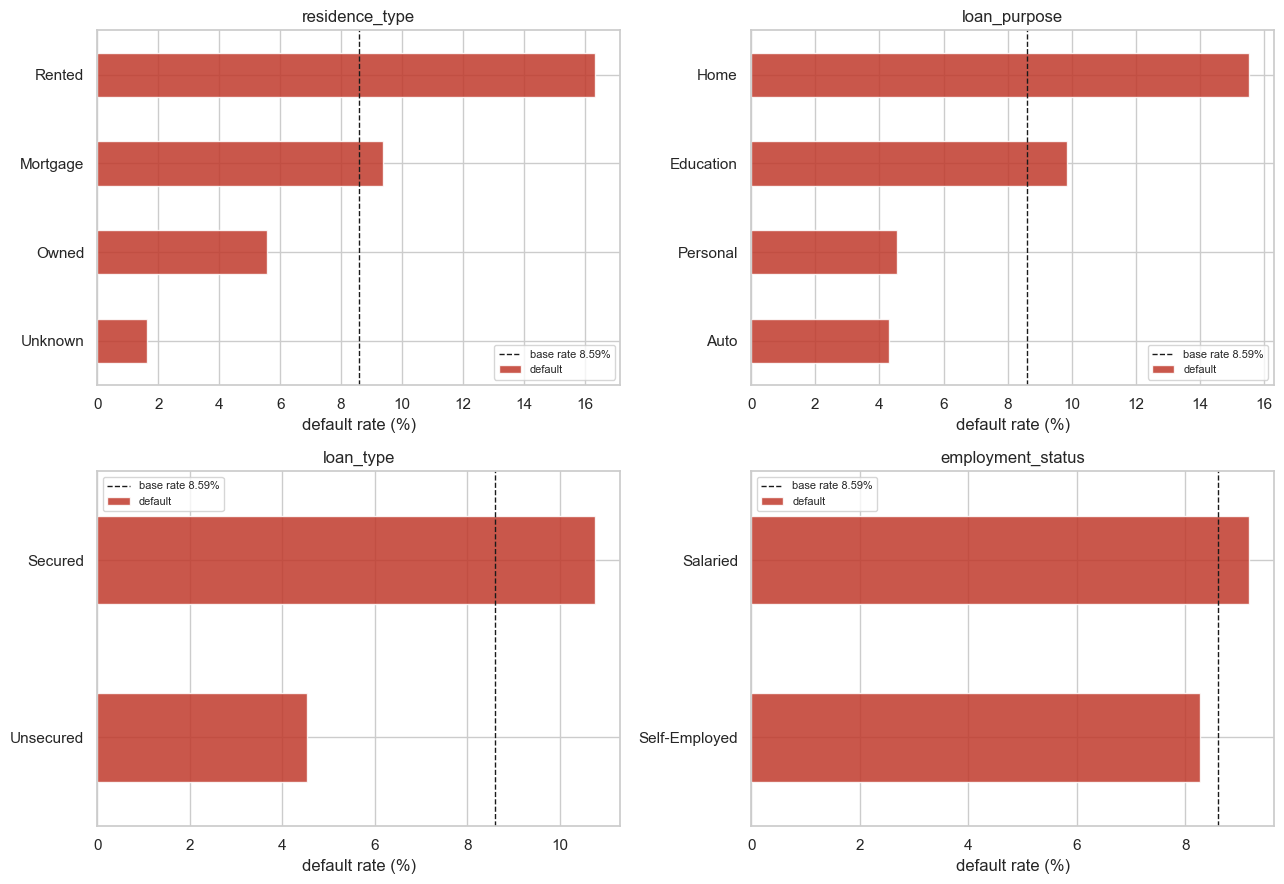

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["residence_type", "loan_purpose", "loan_type", "employment_status"]):
    rates = clean_df.groupby(col)["default"].mean().sort_values() * 100
    rates.plot.barh(ax=ax, color="#c0392b", alpha=0.85)
    ax.axvline(clean_df["default"].mean() * 100, color="k", ls="--", lw=1, label="base rate 8.59%")
    ax.set(xlabel="default rate (%)", ylabel="", title=col)
    ax.legend(fontsize=8)
plt.tight_layout()

Two of these are worth a comment:

* **Rented (16.2%) vs Owned (5.6%)** - a 3x spread. Owning property is both a wealth signal
  and, for a secured loan, a fallback.
* **Secured (10.8%) defaults *more* than Unsecured (4.5%)**, which looks backwards. It is a
  composition effect: `Home` loans are secured and default at 15.5%, and they dominate the
  secured book. The model sees `loan_purpose` too, so it can separate the two.

### 4.4 The numeric features

In [15]:
feat = build_features(clean_df)
y = clean_df["default"].to_numpy()

from sklearn.metrics import roc_auc_score
numeric = feat.select_dtypes("number")
single = pd.DataFrame({
    "feature": numeric.columns,
    "auc_alone": [max(roc_auc_score(y, numeric[c]), 1 - roc_auc_score(y, numeric[c])) for c in numeric.columns],
}).sort_values("auc_alone", ascending=False).reset_index(drop=True)
single.round(4)

,feature,auc_alone
0,credit_utilization_ratio,0.8773
1,delinquency_ratio,0.7259
2,loan_to_income,0.6906
3,balance_to_loan,0.6761
4,avg_dpd_per_delinquency,0.6539
5,loan_tenure_months,0.6273
6,emi_to_monthly_income,0.6215
7,total_loan_months,0.6093
8,age,0.5710
9,loan_to_sanction,0.5662


## 5. Why the model scores 0.988 AUC - the section that matters

An AUC of 0.988 on a credit model should set off alarms. A real consumer-credit scorecard
lands at 0.70-0.80. So the first question is: **is this leakage?**

It is not. The evidence:

1. Every feature is application-time. The post-disbursal columns
   (`principal_outstanding`, `net_disbursement`, `processing_fee`, `gst`,
   `installment_start_dt`) are excluded, and `tests/test_features.py` asserts they can
   never re-enter.
2. The leakage ablation adds `principal_outstanding` back and AUC moves by
   **-0.0001** - it contributes nothing. Its raw correlation with `default` is -0.011.
3. The out-of-time holdout, trained only on pre-July-2023 loans, still scores 0.9855.
   Leakage does not survive a time split.

The real explanation is that **the target is nearly a deterministic function of two
bureau features**. Look at the joint distribution below: borrowers with low utilisation
and no delinquency default at a rate of *exactly zero* - 0 out of 8,150.

Real borrowers do not behave like that. This is generated data, and the generator used a
clean function of these features. So the model is correct and the pipeline is sound, but
**the absolute metrics do not transfer to a real portfolio**. What transfers is the method.

In [16]:
cu = pd.cut(clean_df.credit_utilization_ratio, [-1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
by_cu = clean_df.groupby(cu, observed=True)["default"].agg(n="size", rate="mean")
by_cu["rate_pct"] = (by_cu["rate"] * 100).round(2)
print("default rate by credit utilisation - monotone and very steep:")
print(by_cu[["n", "rate_pct"]])

default rate by credit utilisation - monotone and very steep:
                             n  rate_pct
credit_utilization_ratio                
(-1, 10]                  7425      1.12
(10, 20]                  6709      1.15
(20, 30]                  6521      1.20
(30, 40]                  5019      1.49
(40, 50]                  4866      2.06
(50, 60]                  4787      4.55
(60, 70]                  3319      5.82
(70, 80]                  3365     11.47
(80, 90]                  3481     25.91
(90, 100]                 4500     48.56


cell counts:
delinquency  none  0-10%  10-30%  >30%
utilisation                           
<30          8150   6090    4491  1924
30-60        5964   4178    3189  1341
60-80        2708   1893    1468   615
>80          3171   2276    1763   771


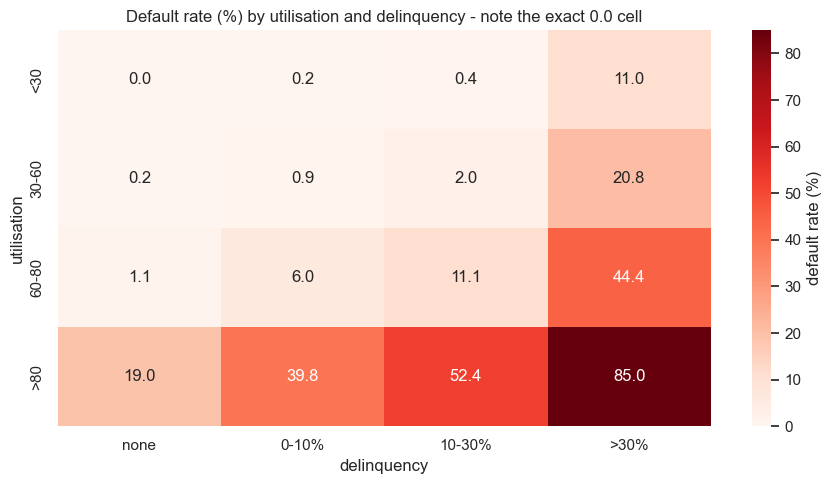

In [17]:
dq = clean_df.delinquent_months / clean_df.total_loan_months
grid = clean_df.assign(
    utilisation=pd.cut(clean_df.credit_utilization_ratio, [-1, 30, 60, 80, 100],
                       labels=["<30", "30-60", "60-80", ">80"]),
    delinquency=pd.cut(dq, [-0.01, 0, 0.1, 0.3, 1.0],
                       labels=["none", "0-10%", "10-30%", ">30%"]),
)
pivot = grid.pivot_table(index="utilisation", columns="delinquency", values="default",
                         aggfunc="mean", observed=True) * 100
counts = grid.pivot_table(index="utilisation", columns="delinquency", values="default",
                          aggfunc="size", observed=True)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", ax=ax,
            cbar_kws={"label": "default rate (%)"})
ax.set_title("Default rate (%) by utilisation and delinquency - note the exact 0.0 cell")
plt.tight_layout()

print("cell counts:")
print(counts)

### Conclusions carried into the model

1. Cleaning is deterministic and fully specified - 22 typos fixed, 62 nulls categorised,
   8 rows dropped, 7 fees repaired, 49,992 rows out.
2. The feature set is application-time only. The exclusions are enforced by tests.
3. `credit_utilization_ratio` and `delinquency_ratio` dominate; the affordability ratios
   add the rest.
4. The headline metrics are real for *this dataset* and should be quoted with the caveat
   that the data is synthetic.

Next: `python -m src.train`.